# <font color = Blue> **Trabalho Final — Problema 05 - Gasolina EUA**

**`Objetivo do trabalho`**:  modelar um *problema real* e fazer predição utilizando os modelos de séries temporais estudados na disciplina.

**`Problema Real`**: Modelagem e predição de volume semanal de gasolina disponibilizado ao mercado dos Estados Unidos, expresso como média diária - **de 08/02/1991 a 20/01/2017**.

**`Tarefa`**: encontrar o melhor modelo e fazer a predição (**forecast**) de volume semanal de gasolina disponibilizado ao mercado dos Estados Unidos, expresso como média diária para um horizonte **`h`**, que será definido adiante.


## <font color = Blue> **Configuração Inicial e Carregamento da Série**
Vamos instalar/importar as bibliotecas necessárias e carregar a série temporal.

- **Bibliotecas básicas**

In [1]:
#Bibliotecas básicas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

- **Carregamento da Série `Gasolina EUA`**

Fonte e preparação: U.S. Energy Information Administration (EIA), série WGFUPUS2. Observações semanais, em milhões de barris/dia; indicador de oferta ao mercado, usado como aproximação da demanda. Calendário semanal alinhado às datas da EIA; o registro de 10/10/1997, ausente no XLS atual da EIA, foi preservado da série publicada fpp2::gasoline (8,221). Os demais valores coincidem integralmente. Fonte complementar: https://pkg.robjhyndman.com/fpp2/reference/gasoline.html . Fonte: https://www.eia.gov/dnav/pet/hist/LeafHandler.ashx?n=PET&s=WGFUPUS2&f=W

O CSV será carregado diretamente do repositório GitHub `MiroPlacido/Datasets`: `AST_2026_Problema_05_Gasolina_EUA.csv`.


In [2]:
url = 'https://raw.githubusercontent.com/MiroPlacido/Datasets/refs/heads/main/AST_2026_Problema_05_Gasolina_EUA.csv'
df = pd.read_csv(url)

# Visualização do df
df.head()


,Data,Volume_Milhoes_Barris_Dia
0,1991-02-08,6.621
1,1991-02-15,6.433
2,1991-02-22,6.582
3,1991-03-01,7.224
4,1991-03-08,6.875


In [3]:
# Identificando a data e setando como índice
df["Data"] = pd.to_datetime(df["Data"])
df = df.set_index("Data")

# Configurar frequência para SEMANAL (para evitar warnings de inferência)
df.index.freq = 'W-FRI'

# Visualizando
df.head()


,Volume_Milhoes_Barris_Dia
Data,
1991-02-08,6.621
1991-02-15,6.433
1991-02-22,6.582
1991-03-01,7.224
1991-03-08,6.875


- **Plot da série ORIGINAL**

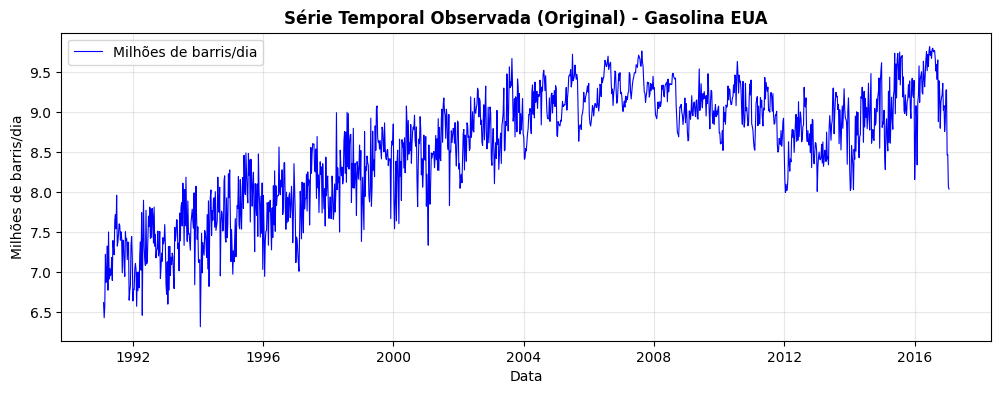

In [4]:
# Visualização da série
plt.figure(figsize=(12, 4))
plt.plot(df, label='Milhões de barris/dia', color='blue', linewidth=0.8)
plt.title('Série Temporal Observada (Original) - Gasolina EUA', fontweight = "bold")
plt.xlabel('Data')
plt.ylabel('Milhões de barris/dia')
plt.grid(True, alpha = 0.3)
plt.legend()
plt.show()


## <font color = Blue> **Parte 1 - Divisão ($split$) da série temporal**


- **Defina e justifique o horizonte `h` de predição**.
- Um horizonte múltiplo do período sazonal `m` é conveniente;
- Reserve os **últimos `h` semanas para teste**, utilizando os dados anteriores como treino e validação;


- **Plot o split da série, isto é, os conjuntos de treino e teste**

## <font color = Blue> **Parte 2 - Tratamento da Série (Detecção e tratamento de anomalias)**


Verifique se o conjunto de treino precisa de algum tratamento. Deixe clara sua escolha, explicando o motivo.
- **Obs:** a escolha pode ser "nada a ajustar".



## <font color = Blue> **Parte 3 - Análise e Diagnóstico**
- Faça plot de um período curto do conjunto de treino (trecho ampliado) para identificar visualmente sazonalidade;
- Faça análises de autocorrelação, estacionariedade e sazonalidade utilizando o conjunto de treino.


## <font color = Blue> **Parte 4 - Treinamento e seleção do modelo**

- Compare **ETSModel, ARIMA, SARIMA, árvore de decisão, Prophet e LSTM**, justificando eventual não aplicação;
- Para seleção do modelo e seus hiperparâmetros, utilize **Cross Validation Temporal exclusivamente dentro do conjunto de treino**, com as mesmas janelas para todos os candidatos e blocos de validação de comprimento **`h`**;
- Selecione pelo **RMSE médio das janelas de validação**, calculado na escala original (milhões de barris por dia);
- Todos os modelos devem prever os **`h` períodos a partir da mesma origem**, sem utilizar valores reais do bloco previsto. Para árvore de decisão e LSTM, explicite a estratégia de previsão (recursiva, direta ou de múltiplas saídas).


## <font color = Blue> **Parte 5 - Avaliação do modelo no conjunto de teste**

- **Treine o modelo escolhido em todo o conjunto de treino**;
- **Avalie o modelo (escolhido na Parte 4) no conjunto de teste**. Para isso:
  - Faça a predição dos **`h` semanas**, sem utilizar valores reais do teste para atualizar as previsões, e compare com os dados observados;
  - Inclua **intervalo de previsão de 95% quando o modelo oferecer esse recurso**; caso contrário, justifique sua ausência;
  - Calcule o **RMSE no conjunto de teste, na escala original**;
- Não utilize o resultado do teste para trocar ou reajustar a configuração do modelo escolhido.


## <font color = Blue> **Parte 6 - Predição (forecast)**

- **Após concluir a avaliação, treine o modelo escolhido na série completa (treino + teste)**, mantendo a configuração selecionada;
- **Faça a predição para os próximos `h` semanas**, incluindo plot e intervalo de previsão de 95% quando disponível; caso contrário, justifique sua ausência.
